# 07 · Bibliotecas: usar, acelerar, empaquetar, publicar, contribuir

La verdadera fuerza de Python es su ecosistema de bibliotecas. Este módulo las mira desde todos los ángulos:
usarlas bien, hacer rápido el código lento con extensiones compiladas, convertir tu propio código en un
paquete instalable, publicarlo, gestionar versiones sin romper a tus usuarios y contribuir a los proyectos de
los que dependes.

**Aprenderás**
1. Encontrar e inspeccionar bibliotecas: versiones, dependencias, documentación
2. Por qué los bucles en Python puro son lentos y cuatro formas de acelerarlos: NumPy, Numba, Cython y C (medido)
3. Empaquetado: un `pyproject.toml`, construir un wheel e instalarlo en un entorno limpio
4. Publicar en PyPI de forma segura
5. Versiones: versionado semántico, especificadores, obsolescencias y compatibilidad hacia atrás
6. Convertirte en colaborador

## 1. Inspeccionar las bibliotecas instaladas

In [1]:
from importlib.metadata import version, requires, metadata
import numpy

print("numpy", version("numpy"), "from", numpy.__file__)
print("pandas requiere:", [r for r in (requires("pandas") or []) if "extra" not in r])
print("resumen:", metadata("polars")["Summary"])
print(numpy.clip.__doc__.strip().splitlines()[0])      # help(numpy.clip) imprime la documentación completa

numpy 2.5.4 from /home/patito/Developments/academy/python/.venv/lib/python3.12/site-packages/numpy/__init__.py
pandas requiere: ['numpy>=1.22.4; python_version < "3.11"', 'numpy>=1.23.2; python_version == "3.11"', 'numpy>=1.26.0; python_version >= "3.12"', 'python-dateutil>=2.8.2', 'pytz>=2020.1', 'tzdata>=2022.7']
resumen: Blazingly fast DataFrame library
Clip (limit) the values in an array.


## 2. Acelerar un bucle crítico
Python ejecuta cada operación a través del intérprete, comprobando los tipos cada vez. En bucles numéricos eso
es de decenas a cientos de veces más lento que el código compilado. La misma función, un bucle con mucho
cálculo numérico, implementada de cinco maneras:

In [2]:
import math, time, numpy as np

def py_version(n: int) -> float:
    total = 0.0
    for i in range(1, n):
        total += math.sin(i) * math.sqrt(i) / i
    return total

def numpy_version(n: int) -> float:
    i = np.arange(1, n, dtype=np.float64)
    return float(np.sum(np.sin(i) * np.sqrt(i) / i))

N = 5_000_000
def bench(fn, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); value = fn(N); best = min(best, time.perf_counter() - t0)
    return best, value

timings = {}
timings["Python puro"] = bench(py_version, repeat=1)
timings["NumPy (vectorizado)"] = bench(numpy_version)
for k, (t, v) in timings.items():
    print(f"{k:<22}{t:8.3f} s   resultado {v:.6f}")

Python puro              1.662 s   resultado 1.044289
NumPy (vectorizado)      0.187 s   resultado 1.044289


**Numba** compila una función de Python a código máquina la primera vez que se llama (compilación justo a
tiempo, JIT). Sigues escribiendo bucles; solo añades un decorador.

In [3]:
from numba import njit

@njit(cache=False)
def numba_version(n):
    total = 0.0
    for i in range(1, n):
        total += math.sin(i) * math.sqrt(i) / i
    return total

numba_version(10)                                   # la primera llamada compila; no se mide
timings["Numba (JIT)"] = bench(numba_version)
print(f"Numba {timings['Numba (JIT)'][0]:.3f} s, resultado {timings['Numba (JIT)'][1]:.6f}")

Numba 0.148 s, resultado 1.044289


**Cython** es un superconjunto de Python que se compila a C. Declarar tipos de C (`cdef double`) es lo que lo
hace rápido. `pyximport` compila un archivo `.pyx` al importarlo; los paquetes reales lo compilan al
construirse.

In [4]:
import os, sys, tempfile, importlib, textwrap
work = tempfile.mkdtemp()
with open(os.path.join(work, "fastloop.pyx"), "w") as f:
    f.write(textwrap.dedent("""
        from libc.math cimport sin, sqrt
        def cython_version(long n):
            cdef double total = 0.0
            cdef long i
            for i in range(1, n):
                total += sin(i) * sqrt(i) / i
            return total
    """))
import pyximport
pyximport.install(build_dir=os.path.join(work, "build"), language_level=3, inplace=False)
sys.path.insert(0, work)
fastloop = importlib.import_module("fastloop")
timings["Cython (tipado)"] = bench(fastloop.cython_version)
print(f"Cython {timings['Cython (tipado)'][0]:.3f} s, resultado {timings['Cython (tipado)'][1]:.6f}")

Cython 0.147 s, resultado 1.044289


**C a través de `ctypes`**: escribe la función en C, compílala como biblioteca compartida y llámala desde
Python. Así envuelven muchas bibliotecas código C existente (otras usan `cffi` o, para C++, `pybind11`).

In [5]:
import ctypes, shutil, subprocess
c_src = os.path.join(work, "loop.c")
lib_path = os.path.join(work, "libloop.so")
with open(c_src, "w") as f:
    f.write("""
#include <math.h>
double c_version(long n) {
    double total = 0.0;
    for (long i = 1; i < n; i++) total += sin((double)i) * sqrt((double)i) / i;
    return total;
}
""")
if shutil.which("gcc"):
    subprocess.run(["gcc", "-O2", "-shared", "-fPIC", c_src, "-o", lib_path, "-lm"], check=True)
    lib = ctypes.CDLL(lib_path)
    lib.c_version.argtypes, lib.c_version.restype = [ctypes.c_long], ctypes.c_double
    timings["C con ctypes"] = bench(lib.c_version)
    print(f"C {timings['C con ctypes'][0]:.3f} s, resultado {timings['C con ctypes'][1]:.6f}")
else:
    print("no se encontró un compilador de C: instala gcc (Linux), las herramientas de línea de órdenes de Xcode (macOS) o Build Tools (Windows)")

C 0.145 s, resultado 1.044289


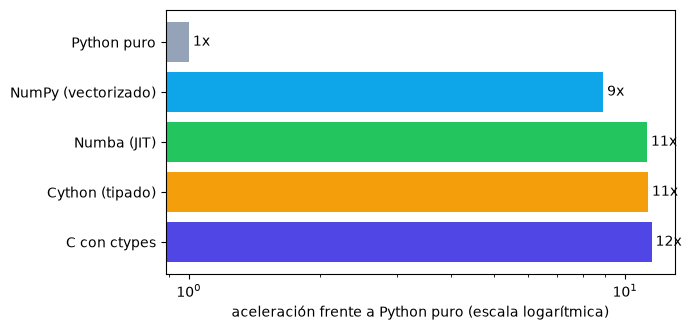

In [6]:
import matplotlib.pyplot as plt
base = timings["Python puro"][0]
names = list(timings)
speedups = [base / timings[k][0] for k in names]
plt.figure(figsize=(7, 3.4))
plt.barh(names, speedups, color=["#94a3b8", "#0ea5e9", "#22c55e", "#f59e0b", "#4f46e5"][:len(names)])
plt.gca().invert_yaxis(); plt.xscale("log"); plt.xlabel("aceleración frente a Python puro (escala logarítmica)")
for y, s in enumerate(speedups):
    plt.text(s, y, f" {s:,.0f}x", va="center")
plt.tight_layout(); plt.show()

Las cinco coinciden en el resultado con muchos decimales, y cada alternativa es aproximadamente diez veces más
rápida que el bucle en Python puro. Quedan cerca unas de otras porque el tiempo que queda se pasa dentro de
`sin` y `sqrt`; en bucles con cuerpos más baratos (contar, comparar, aritmética sencilla) la diferencia con
Python puro suele ser de 50 a 100 veces. Cuál elegir:

| Opción | Esfuerzo | Mejor cuando |
|---|---|---|
| vectorización con NumPy | reescribir como operaciones con arrays | el cálculo se expresa sobre arrays completos |
| Numba | un decorador | bucles numéricos sobre arrays de NumPy y escalares |
| Cython | un archivo `.pyx` tipado más un paso de compilación | además necesitas llamar a bibliotecas de C o distribuir un paquete compilado |
| C / C++ (ctypes, cffi, pybind11) | escribir y compilar código nativo | envolver una biblioteca nativa existente |
| Rust (PyO3, maturin) | Rust | bibliotecas nuevas donde el rendimiento es crítico (Polars, Pydantic y ruff se construyen así) |

**Perfila siempre primero** (`cProfile`, `line_profiler`, `py-spy`): acelera la función que de verdad consume
el tiempo.

## 3. Empaquetar tu propia biblioteca
Un paquete es una carpeta con un `__init__.py`; una *distribución* (un **wheel**) es lo que instala `pip`.
Todos los metadatos viven en `pyproject.toml`. A continuación se crea una biblioteca diminuta, `ministats`, se
construye como wheel, se comprueba y se instala en un entorno limpio.

In [7]:
import pathlib
pkg = pathlib.Path(tempfile.mkdtemp()) / "ministats"
(pkg / "src" / "ministats").mkdir(parents=True)
(pkg / "tests").mkdir()
(pkg / "src" / "ministats" / "__init__.py").write_text(textwrap.dedent("""
    "Tiny statistics helpers (course example)."
    from importlib.metadata import version as _v
    __version__ = _v("ministats")

    def mean(values):
        values = list(values)
        if not values:
            raise ValueError("mean of an empty sequence")
        return sum(values) / len(values)

    def zscores(values):
        values = list(values)
        m = mean(values)
        sd = (sum((v - m) ** 2 for v in values) / len(values)) ** 0.5
        return [(v - m) / sd for v in values]
"""))
(pkg / "tests" / "test_basic.py").write_text("from ministats import mean\n\ndef test_mean():\n    assert mean([1, 2, 3]) == 2\n")
(pkg / "README.md").write_text("# ministats\n\nTiny statistics helpers.\n")
(pkg / "LICENSE").write_text("MIT License\n")
(pkg / "pyproject.toml").write_text(textwrap.dedent("""
    [build-system]
    requires = ["setuptools>=70"]
    build-backend = "setuptools.build_meta"

    [project]
    name = "ministats"
    version = "0.1.0"
    description = "Tiny statistics helpers (course example)"
    readme = "README.md"
    license = "MIT"
    requires-python = ">=3.10"
    dependencies = []                      # e.g. ["numpy>=1.26"]
    authors = [{ name = "Your Name" }]
    classifiers = ["Programming Language :: Python :: 3"]

    [project.optional-dependencies]
    dev = ["pytest>=8"]

    [project.urls]
    Homepage = "https://example.org/ministats"
"""))
print(subprocess.run(["find", str(pkg), "-type", "f"], capture_output=True, text=True).stdout)

/tmp/tmp2i54is8t/ministats/src/ministats/__init__.py
/tmp/tmp2i54is8t/ministats/README.md
/tmp/tmp2i54is8t/ministats/LICENSE
/tmp/tmp2i54is8t/ministats/tests/test_basic.py
/tmp/tmp2i54is8t/ministats/pyproject.toml



In [8]:
# construir un sdist (archivo fuente) y un wheel; --no-isolation reutiliza el setuptools de este entorno (funciona sin conexión)
r = subprocess.run([sys.executable, "-m", "build", "--no-isolation", str(pkg)], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
dist = sorted((pkg / "dist").iterdir())
print([p.name for p in dist])
print(subprocess.run([sys.executable, "-m", "twine", "check", *map(str, dist)], capture_output=True, text=True).stdout)

Successfully built ministats-0.1.0.tar.gz and ministats-0.1.0-py3-none-any.whl
['ministats-0.1.0-py3-none-any.whl', 'ministats-0.1.0.tar.gz']


Checking /tmp/tmp2i54is8t/ministats/dist/ministats-0.1.0-py3-none-any.whl: PASSED
Checking /tmp/tmp2i54is8t/ministats/dist/ministats-0.1.0.tar.gz: PASSED



In [9]:
import venv, zipfile
wheel = next(p for p in dist if p.suffix == ".whl")
print("dentro del wheel:", [n for n in zipfile.ZipFile(wheel).namelist()])

clean = pathlib.Path(tempfile.mkdtemp()) / "env"
venv.create(clean, with_pip=True)
py = clean / "bin" / "python"
subprocess.run([py, "-m", "pip", "install", "-q", str(wheel)], check=True)
print(subprocess.run([py, "-c", "import ministats; print(ministats.__version__, ministats.zscores([2, 4, 6]))"],
                     capture_output=True, text=True).stdout)

dentro del wheel: ['ministats/__init__.py', 'ministats-0.1.0.dist-info/licenses/LICENSE', 'ministats-0.1.0.dist-info/METADATA', 'ministats-0.1.0.dist-info/WHEEL', 'ministats-0.1.0.dist-info/top_level.txt', 'ministats-0.1.0.dist-info/RECORD']


0.1.0 [-1.224744871391589, 0.0, 1.224744871391589]



## 4. Publicar
1. Crea cuentas en **TestPyPI** (test.pypi.org) y **PyPI** (pypi.org), con autenticación en dos pasos.
2. Sube primero a TestPyPI e instala desde allí: `pip install -i https://test.pypi.org/simple/ ministats`.
3. Publica en PyPI desde la integración continua con **trusted publishing** (publicación de confianza): GitHub
   Actions demuestra su identidad ante PyPI, así que no se guarda ningún token de API en ninguna parte.

In [10]:
print("""# .github/workflows/publish.yml: publicar al crear una release en GitHub
name: publish
on:
  release:
    types: [published]
jobs:
  pypi:
    runs-on: ubuntu-latest
    environment: pypi
    permissions:
      id-token: write          # trusted publishing: sin contraseña ni token guardados
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: { python-version: "3.12" }
      - run: python -m pip install build && python -m build
      - uses: pypa/gh-action-pypi-publish@release/v1
""")

# .github/workflows/publish.yml: publicar al crear una release en GitHub
name: publish
on:
  release:
    types: [published]
jobs:
  pypi:
    runs-on: ubuntu-latest
    environment: pypi
    permissions:
      id-token: write          # trusted publishing: sin contraseña ni token guardados
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: { python-version: "3.12" }
      - run: python -m pip install build && python -m build
      - uses: pypa/gh-action-pypi-publish@release/v1



## 5. Versiones y compatibilidad hacia atrás
**Versionado semántico** (`MAYOR.MENOR.PARCHE`): PARCHE corrige errores, MENOR añade funciones sin romper
nada y MAYOR rompe algo. Así los usuarios pueden depender de `>=2.3,<3`.

In [11]:
from packaging.version import Version
from packaging.specifiers import SpecifierSet

print(sorted(["1.10.0", "1.9.2", "2.0.0rc1", "1.10.0.post1"], key=Version))
spec = SpecifierSet(">=2.2,<3")
print({v: Version(v) in spec for v in ["2.1.4", "2.2.0", "2.9.9", "3.0.0"]})
print(Version("2.0.0rc1").is_prerelease, Version("1.4.2").release)
print("versión compatible ~=1.4.2 significa >=1.4.2,<1.5:", Version("1.4.9") in SpecifierSet("~=1.4.2"))

['1.9.2', '1.10.0', '1.10.0.post1', '2.0.0rc1']
{'2.1.4': False, '2.2.0': True, '2.9.9': True, '3.0.0': False}
True (1, 4, 2)
versión compatible ~=1.4.2 significa >=1.4.2,<1.5: True


Eliminar o renombrar algo rompe el código de tus usuarios. La forma educada es un **periodo de obsolescencia**:
mantener funcionando el nombre antiguo, avisar y eliminarlo solo en la siguiente versión mayor.

In [12]:
import warnings, functools

def deprecated(new_name: str, removed_in: str):
    def decorate(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            warnings.warn(f"{func.__name__}() está obsoleta y se eliminará en la versión {removed_in}; "
                          f"usa {new_name}() en su lugar", DeprecationWarning, stacklevel=2)
            return func(*args, **kwargs)
        return wrapper
    return decorate

def arithmetic_mean(values, *, skipna: bool = False):        # API nueva (opción nueva solo por nombre)
    values = [v for v in values if not (skipna and v is None)]
    return sum(values) / len(values)

@deprecated("arithmetic_mean", removed_in="2.0")
def average(values):                                           # el nombre antiguo sigue funcionando por ahora
    return arithmetic_mean(values)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    print(average([1, 2, 3]), arithmetic_mean([1, None, 3], skipna=True))
print(caught[0].category.__name__, ":", caught[0].message)

2.0 2.0


Reglas prácticas de compatibilidad para autores de bibliotecas:
- Los parámetros nuevos llevan valor por defecto y son solo por nombre (`*,`), para que las llamadas existentes no cambien de significado.
- Nunca cambies lo que devuelve una llamada existente en una versión menor.
- Mantén un `CHANGELOG.md`; marca con claridad los cambios incompatibles.
- Prueba en la integración continua con las versiones más antiguas y más nuevas de Python y de las dependencias que soportas.
- Declara `requires-python` y los rangos de dependencias con honestidad; no fijes versiones exactas en una biblioteca.

## 6. Convertirte en colaborador
1. **Usa el proyecto y lee su guía CONTRIBUTING y su código de conducta.**
2. Empieza por algo pequeño: arreglos de documentación, una prueba que falle y reproduzca un error, incidencias etiquetadas *good first issue*.
3. Habla antes de hacer cambios grandes: abre o comenta primero una incidencia.
4. Haz un fork, crea una rama, instala el proyecto en modo editable (`pip install -e ".[dev]"`) y ejecuta sus pruebas.
5. Haz un único cambio concreto, con pruebas, formateado con las herramientas del proyecto.
6. Abre una pull request que explique el *porqué*, enlaza la incidencia y responde a la revisión con amabilidad y paciencia.
7. Algunos proyectos piden firmar un acuerdo de licencia de contribución; comprueba la licencia de cualquier cosa que copies.

Revisar pull requests de otras personas, clasificar incidencias y responder preguntas también son
contribuciones, y es lo que más suele faltar a quienes mantienen los proyectos.

## Ejercicios
1. Añade una función `median` a `ministats` con su prueba, sube la versión a `0.2.0`, reconstruye e instala el wheel nuevo encima del antiguo.
2. Usa `cProfile` (`python -m cProfile -s cumtime script.py`) para encontrar la función más lenta de uno de tus scripts.
3. Lleva `py_version` a Numba con `parallel=True` y `numba.prange`. ¿Cuánto más rápida es en tus núcleos?
4. Elige una biblioteca que uses, abre su gestor de incidencias y lee tres tickets *good first issue*.